<a href="https://colab.research.google.com/github/Naveenr1425/FairFlash/blob/main/24cs133_Household_Electricity_Consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files

uploaded = files.upload()

Saving household_power_consumption.txt to household_power_consumption (1).txt


In [7]:
import pandas as pd #importing
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
df = pd.read_csv(                          #load dataset
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print(df.head())
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  
Date                         0
Time       

In [9]:
# Combine Date and Time into a timestamp
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)                                              #explore dataset structure

# Convert measurement columns to numeric
feature_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort records chronologically
df = df.sort_values("Datetime").reset_index(drop=True)

# Remove rows with invalid timestamps
df = df.dropna(subset=["Datetime"]).reset_index(drop=True)

# Identify rows without missing numerical measurements
valid = df[feature_cols].notna().all(axis=1)

# Select 10,000 consecutive valid minute-level records
window_size = 10000
selected_start = None

for start in range(len(df) - window_size + 1):
    end = start + window_size

    if not valid.iloc[start:end].all():
        continue

    timestamps = df["Datetime"].iloc[start:end]
    differences = timestamps.diff().iloc[1:]

    if differences.eq(pd.Timedelta(minutes=1)).all():
        selected_start = start
        break

if selected_start is None:
    raise ValueError(
        "No uninterrupted interval of 10,000 valid minute-level "
        "records was found. Use a contiguous hourly subset instead."
    )

df = df.iloc[
    selected_start:selected_start + window_size
].copy().reset_index(drop=True)

print("Selected records:", len(df))
print("Start:", df["Datetime"].iloc[0])
print("End:", df["Datetime"].iloc[-1])
print("Missing values:", df[feature_cols].isnull().sum().sum())

Selected records: 10000
Start: 2006-12-21 11:25:00
End: 2006-12-28 10:04:00
Missing values: 0


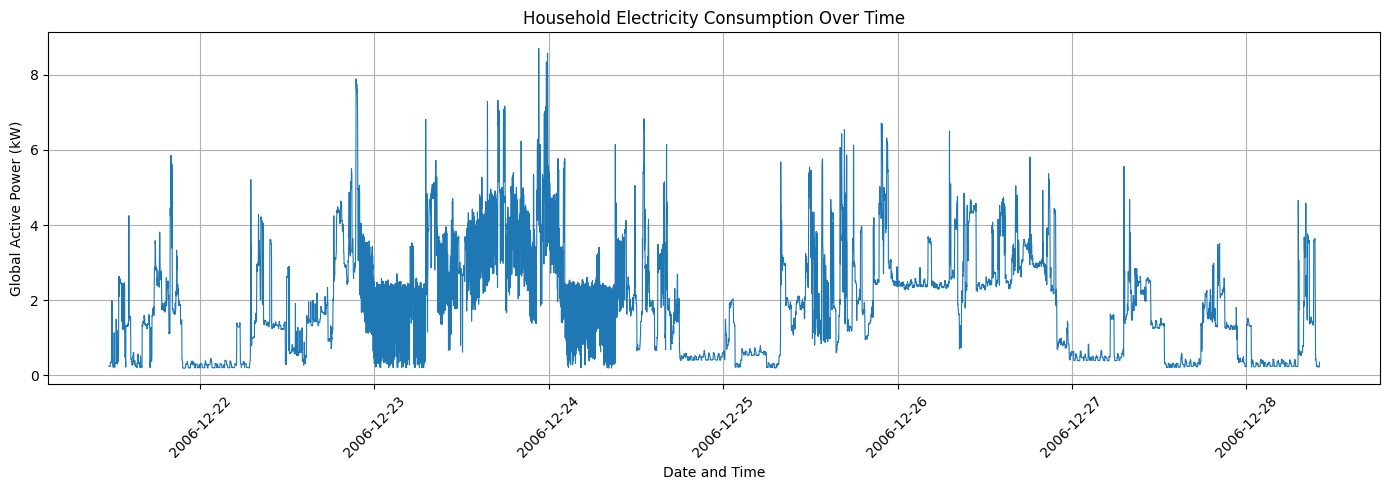

In [10]:
import matplotlib.pyplot as plt           #Identify missing values

plt.figure(figsize=(14, 5))

plt.plot(
    df["Datetime"],
    df["Global_active_power"],
    linewidth=0.8
)

plt.title("Household Electricity Consumption Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [11]:
from sklearn.preprocessing import MinMaxScaler                #Understand data features

# Select numerical features
data = df[feature_cols].copy()

# Split chronologically: 70% training, 15% validation, 15% testing
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = data.iloc[:train_end]
val_data = data.iloc[train_end:val_end]
test_data = data.iloc[val_end:]

# Normalize features using training data only
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Normalization completed successfully!")
print("Training records:", len(train_scaled))
print("Validation records:", len(val_scaled))
print("Testing records:", len(test_scaled))

print("\nNormalized training data (first 5 rows):")
print(train_scaled[:5])


Normalization completed successfully!
Training records: 7000
Validation records: 1500
Testing records: 1500

Normalized training data (first 5 rows):
[[0.00611477 0.         0.5909719  0.00552486 0.         0.
  0.        ]
 [0.00611477 0.         0.59511746 0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.55504376 0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.57392906 0.00552486 0.         0.
  0.        ]
 [0.00587959 0.         0.5720866  0.00552486 0.         0.
  0.        ]]


In [12]:
import numpy as np                     #Load and handle missing values

# Use the previous 60 minutes to predict the next minute
sequence_length = 60

# Target column: Global_active_power
target_index = feature_cols.index("Global_active_power")


# Function to generate sequences
def create_sequences(data, sequence_length, target_index):
    X = []
    y = []

    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i, target_index])

    return np.array(X), np.array(y)


# Generate training sequences
X_train, y_train = create_sequences(
    train_scaled,
    sequence_length,
    target_index
)


# Generate validation sequences
val_context = np.concatenate(
    [train_scaled[-sequence_length:], val_scaled],
    axis=0
)

X_val, y_val = create_sequences(
    val_context,
    sequence_length,
    target_index
)


# Generate testing sequences
test_context = np.concatenate(
    [val_context[-sequence_length:], test_scaled],
    axis=0
)

X_test, y_test = create_sequences(
    test_context,
    sequence_length,
    target_index
)


# Display results
print("Sequence generation completed successfully!")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Sequence generation completed successfully!
X_train shape: (6940, 60, 7)
y_train shape: (6940,)
X_val shape: (1500, 60, 7)
y_val shape: (1500,)
X_test shape: (1500, 60, 7)
y_test shape: (1500,)


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Build the LSTM model
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(sequence_length, len(feature_cols))
    ),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse"
)

# Display the model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

print("LSTM model training completed!")

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - loss: 0.0216 - val_loss: 0.0125
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 98ms/step - loss: 0.0119 - val_loss: 0.0100
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 18s 77ms/step - loss: 0.0111 - val_loss: 0.0077
Epoch 4/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - loss: 0.0097 - val_loss: 0.0054
Epoch 5/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - loss: 0.0085 - val_loss: 0.0042
Epoch 6/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - loss: 0.0082 - val_loss: 0.0038
Epoch 7/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0076 - val_loss: 0.0033
Epoch 8/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 89ms/step - loss: 0.0072 - val_loss: 0.0033
Epoch 9/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - loss: 0.0072 - val_loss: 0.0036
Epoch 10/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - loss: 0.0071 - val_loss: 0.0035
Epoch 11/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - loss: 0.0067 - val_loss: 0.0031
Epoch 12/30
109/109 ━━━━━━━━━━━━━━━

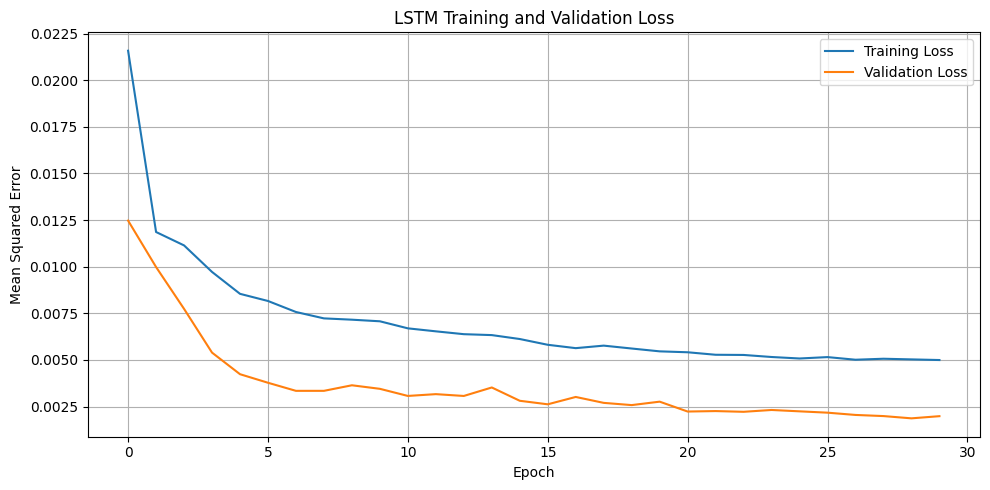

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [16]:
# Generate predictions using the test sequences
y_pred_scaled = model.predict(X_test)

# Extract the scaler parameters for Global_active_power
target_min = scaler.data_min_[target_index]
target_scale = scaler.scale_[target_index]

# Convert normalized values back to kW
y_test_actual = (
    y_test.reshape(-1, 1) - scaler.min_[target_index]
) / target_scale

y_pred_actual = (
    y_pred_scaled - scaler.min_[target_index]
) / target_scale

print("Prediction completed successfully!")
print("Actual test values:", y_test_actual.shape)
print("Predicted test values:", y_pred_actual.shape)

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
Prediction completed successfully!
Actual test values: (1500, 1)
Predicted test values: (1500, 1)


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_pred_actual
    )
)

print("Model Evaluation Results")
print("------------------------")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")

Model Evaluation Results
------------------------
MAE:  0.2171 kW
RMSE: 0.3026 kW


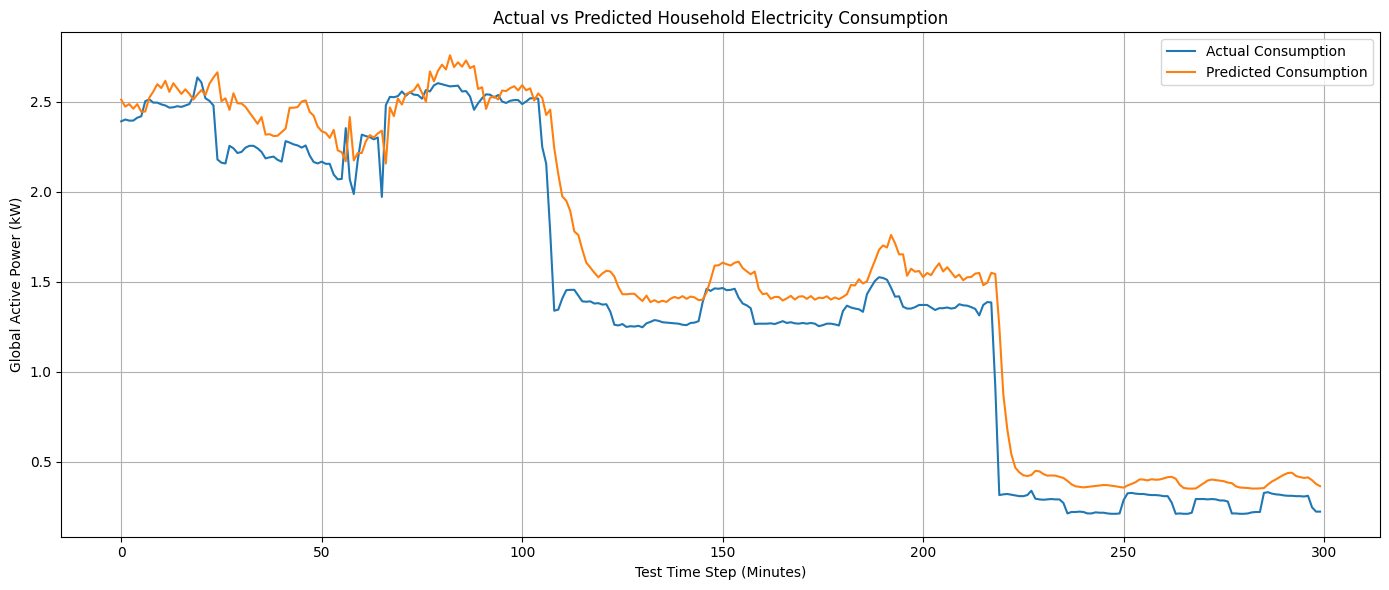

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test_actual[:300],
    label="Actual Consumption"
)

plt.plot(
    y_pred_actual[:300],
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Household Electricity Consumption")
plt.xlabel("Test Time Step (Minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [19]:
import pandas as pd

results = pd.DataFrame({
    "Actual Consumption (kW)": y_test_actual.flatten()[:20],
    "Predicted Consumption (kW)": y_pred_actual.flatten()[:20]
})

results["Absolute Error (kW)"] = abs(
    results["Actual Consumption (kW)"] -
    results["Predicted Consumption (kW)"]
)

print(results.round(4))

    Actual Consumption (kW)  Predicted Consumption (kW)  Absolute Error (kW)
0                     2.390                      2.5104               0.1204
1                     2.400                      2.4718               0.0718
2                     2.394                      2.4858               0.0918
3                     2.394                      2.4599               0.0659
4                     2.410                      2.4855               0.0755
5                     2.418                      2.4430               0.0250
6                     2.502                      2.4446               0.0574
7                     2.512                      2.5210               0.0090
8                     2.494                      2.5555               0.0615
9                     2.494                      2.5960               0.1020
10                    2.484                      2.5749               0.0909
11                    2.478                      2.6152               0.1372

In [20]:
print("HOUSEHOLD ELECTRICITY CONSUMPTION FORECASTING")
print("=" * 50)
print("Model: LSTM Neural Network")
print("Sequence Length: 60 minutes")
print("Evaluation Dataset: Test Data")
print("-" * 50)
print(f"Mean Absolute Error (MAE):  {mae:.4f} kW")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kW")
print("-" * 50)
print("Model evaluation completed successfully!")

HOUSEHOLD ELECTRICITY CONSUMPTION FORECASTING
Model: LSTM Neural Network
Sequence Length: 60 minutes
Evaluation Dataset: Test Data
--------------------------------------------------
Mean Absolute Error (MAE):  0.2171 kW
Root Mean Squared Error (RMSE): 0.3026 kW
--------------------------------------------------
Model evaluation completed successfully!
